# 07. Đánh giá Test chung

Notebook nạp bốn mô hình đã lưu, kiểm tra lại điểm Validation, rồi đánh giá trên cùng tập Test của nhóm. Các cấu hình và trọng số lấy theo bộ bàn giao được ghi trong `validation_manifest.json` ở notebook 06.

| Bước | Dữ liệu | Kết quả |
|---|---|---|
| Đối chiếu đầu vào | CSV, bộ chia, bộ tiền xử lý và mô hình đã lưu | Kiểm tra mã nhận diện file và thứ tự nhãn |
| Kiểm tra nạp lại | Validation chung | Xác nhận dự đoán tái tạo được bảng bàn giao |
| Chấm cuối | Test chung | Bảng điểm, từng lớp, ma trận nhầm lẫn và dự đoán từng sinh viên |

Mô hình được chọn trước bước Test là mô hình đứng đầu Macro-F1 trên Validation. Bảng Test trình bày kết quả của cả bốn phương pháp đã chốt. Khi chạy lại với cùng các file đầu vào, notebook tái tạo bộ kết quả này.

## 1. Đọc bộ bàn giao và kiểm tra dữ liệu

Chạy `06_compare_validation.ipynb` trước để tạo bảng tổng hợp và mã nhận diện của các file đầu vào. File văn bản được thống nhất CRLF thành LF khi tính hash, để các bản clone trên Windows và Linux có thể đối chiếu với nhau.

In [1]:
import hashlib
import json
import platform
import sys
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from IPython.display import Image, display
from torch import nn

here = Path.cwd().resolve()
root = next((folder for folder in (here, *here.parents)
             if (folder / "common/metrics.py").is_file()), None)
if root is None:
    raise FileNotFoundError("Mở thư mục student-dropout-prediction trong VS Code.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from common.metrics import SUMMARY_COLUMNS, confusion_frame, evaluate, per_class_frame, summary_frame
from common.preprocessing import FEATURE_COLUMNS, LABELS, TARGET


def file_sha256(path):
    # Văn bản dùng cùng quy ước xuống dòng với notebook 06, mô hình và hình dùng byte gốc.
    content = path.read_bytes()
    if path.suffix in {".py", ".csv", ".json", ".ipynb", ".md", ".txt"}:
        content = content.replace(b"\r\n", b"\n")
    return hashlib.sha256(content).hexdigest()


comparison_dir = root / "reports/tables/comparison"
manifest_path = comparison_dir / "validation_manifest.json"
if not manifest_path.is_file():
    raise FileNotFoundError("Chạy 06_compare_validation.ipynb để tạo bảng bàn giao trước.")
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
if manifest["hash_mode"] != "binary_for_models_lf_for_text":
    raise ValueError("Quy ước tính hash khác với notebook đánh giá.")
if manifest["labels"] != list(LABELS) or manifest["feature_columns"] != list(FEATURE_COLUMNS):
    raise ValueError("Thứ tự nhãn hoặc cột đầu vào khác bộ bàn giao.")
for relative, expected_hash in manifest["input_sha256"].items():
    if file_sha256(root / relative) != expected_hash:
        raise ValueError(f"File đã thay đổi so với bộ bàn giao. Kiểm tra lại {relative}.")

data_path = root / manifest["dataset"]["path"]
split_path = root / manifest["split"]["path"]
data = pd.read_csv(data_path, sep=";", encoding="utf-8-sig")
data.columns = data.columns.str.strip()
split = json.loads(split_path.read_text(encoding="utf-8"))
if file_sha256(data_path) != manifest["dataset"]["sha256_lf"] or split["sha256"] != file_sha256(data_path):
    raise ValueError("CSV khác dữ liệu dùng để tạo bộ chia.")
if file_sha256(split_path) != manifest["split"]["sha256_lf"] or split["n_rows"] != len(data):
    raise ValueError("Bộ chia khác bản đã bàn giao.")


def checked_rows(name):
    rows = split[name]
    if not isinstance(rows, list) or not rows:
        raise ValueError(f"Tập {name} thiếu danh sách chỉ số dòng.")
    if any(type(row) is not int or not 0 <= row < len(data) for row in rows):
        raise ValueError(f"Tập {name} có chỉ số dòng không hợp lệ.")
    if len(set(rows)) != len(rows):
        raise ValueError(f"Tập {name} chứa dòng trùng.")
    return rows


train_rows = checked_rows("train")
validation_rows = checked_rows("validation")
test_rows = checked_rows("test")
all_rows = train_rows + validation_rows + test_rows
if len(all_rows) != len(set(all_rows)) or set(all_rows) != set(range(len(data))):
    raise ValueError("Ba tập phải tách rời và bao phủ toàn bộ CSV.")
model_names = ["Dummy", "Logistic Regression", "Random Forest", "MLP"]
if [info["name"] for info in manifest["models"]] != model_names:
    raise ValueError("Bộ bàn giao phải có đúng bốn mô hình theo thứ tự chung.")

table_dir = root / "reports/tables/test"
figure_dir = root / "reports/figures/test"
table_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)
print(f"Train {len(train_rows):,} mẫu, Validation {len(validation_rows):,} mẫu, Test {len(test_rows):,} mẫu.")
print(f"Mô hình được chọn từ Validation là {manifest['selected_model']}.")

Train 3,096 mẫu, Validation 664 mẫu, Test 664 mẫu.
Mô hình được chọn từ Validation là Random Forest.


## 2. Nạp mô hình đã chốt

Dummy, Logistic và Random Forest nhận trực tiếp 36 cột gốc qua pipeline đã lưu. MLP dùng checkpoint cùng bộ tiền xử lý riêng. Class `MLP` bên dưới lấy cùng định nghĩa trong `05_mlp.ipynb`, để nạp trọng số ở notebook tổng hợp.

Thông tin phiên bản của từng pipeline được giữ lại khi nạp. Bước đối chiếu Validation ở mục 3 kiểm tra đầu ra của các mô hình trong môi trường đang chạy.

In [2]:
class MLP(nn.Module):
    def __init__(self, n_features, hidden_sizes, dropout, n_classes=len(LABELS)):
        super().__init__()
        layers = []
        width = n_features
        for size in hidden_sizes:
            layers.extend([nn.Linear(width, size), nn.ReLU(), nn.Dropout(dropout)])
            width = size
        layers.append(nn.Linear(width, n_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

# Giữ cùng số luồng CPU với notebook MLP để tái tạo phép tính.
torch.set_num_threads(1)
pipelines = {}
load_warnings = []
for info in manifest["models"]:
    if info["name"] != "MLP":
        with warnings.catch_warnings(record=True) as captured:
            warnings.simplefilter("always")
            pipelines[info["name"]] = joblib.load(root / info["artifact_paths"][0])
        load_warnings.extend({
            "model": info["name"], "message": str(item.message),
        } for item in captured)

mlp_info = next(info for info in manifest["models"] if info["name"] == "MLP")
mlp_meta = json.loads((root / mlp_info["metadata_path"]).read_text(encoding="utf-8"))
checkpoint = torch.load(root / "artifacts/mlp_best.pt", map_location="cpu", weights_only=True)
if checkpoint["labels"] != list(LABELS):
    raise ValueError("Thứ tự nhãn trong checkpoint MLP khác thứ tự chung.")
if (checkpoint["n_features"] != mlp_meta["n_features_after_preprocess"]
        or checkpoint["hidden_sizes"] != mlp_meta["best_config"]["hidden_sizes"]
        or checkpoint["dropout"] != mlp_meta["best_config"]["dropout"]):
    raise ValueError("Kiến trúc MLP khác thông tin bàn giao.")
mlp = MLP(checkpoint["n_features"], checkpoint["hidden_sizes"], checkpoint["dropout"])
mlp.load_state_dict(checkpoint["state_dict"])
mlp.eval()
mlp_preprocessor = joblib.load(root / "artifacts/mlp_preprocessor.joblib")

display(pd.DataFrame([
    {"mô hình": info["name"],
     "file mô hình": ", ".join(info["artifact_paths"]),
     "scikit-learn khi lưu": json.loads((root / info["metadata_path"]).read_text(encoding="utf-8"))["sklearn_version"]}
    for info in manifest["models"]
]))
print(f"Đang chạy Python {platform.python_version()}, scikit-learn {sklearn.__version__}, torch {torch.__version__}.")
if load_warnings:
    display(pd.DataFrame(load_warnings))

,mô hình,file mô hình,scikit-learn khi lưu
0,Dummy,artifacts/dummy_pipeline.joblib,1.9.1
1,Logistic Regression,artifacts/logistic_pipeline.joblib,1.9.1
2,Random Forest,artifacts/random_forest_pipeline.joblib,1.9.1
3,MLP,"artifacts/mlp_best.pt, artifacts/mlp_preproces...",1.9.1


Đang chạy Python 3.13.14, scikit-learn 1.9.1, torch 2.15.0+cpu.


## 3. Kiểm tra mô hình nạp lại trên Validation

Tạo dự đoán cho cùng các chỉ số Validation đã bàn giao. Đối chiếu cả năm metric và toàn bộ ma trận nhầm lẫn với kết quả của từng nhánh trước khi chấm Test.

Pipeline Logistic của lượt chạy này được lưu bằng scikit-learn **1.9.1**. Môi trường đánh giá dùng **1.9.1**. Các kết quả Validation nạp lại đã khớp với bộ bàn giao.

In [3]:
def predict_models(frame):
    predictions = {}
    for name, pipeline in pipelines.items():
        labels = np.asarray(pipeline.predict(frame))
        # predict_proba theo pipeline.classes_, nên sắp lại cột trước khi xuất bảng.
        probabilities = pd.DataFrame(
            pipeline.predict_proba(frame), columns=pipeline.classes_,
        ).loc[:, list(LABELS)].to_numpy()
        predictions[name] = (labels, probabilities)

    features = mlp_preprocessor.transform(frame).astype(np.float32)
    with torch.no_grad():
        logits = mlp(torch.from_numpy(features))
        probabilities = torch.softmax(logits, dim=1).numpy()
    predictions["MLP"] = (np.asarray(checkpoint["labels"])[probabilities.argmax(axis=1)], probabilities)

    for name, (labels, probabilities) in predictions.items():
        if (len(labels) != len(frame) or probabilities.shape != (len(frame), len(LABELS))
                or not np.isin(labels, LABELS).all() or not np.isfinite(probabilities).all()
                or (probabilities < 0).any() or (probabilities > 1).any()):
            raise ValueError(f"Dự đoán hoặc xác suất của {name} không hợp lệ.")
        np.testing.assert_allclose(probabilities.sum(axis=1), np.ones(len(frame)), atol=1e-6)
    return predictions


X_validation = data.iloc[validation_rows].loc[:, list(FEATURE_COLUMNS)]
y_validation = data.iloc[validation_rows][TARGET]
reloaded_validation = predict_models(X_validation)
validation_check = []
for info in manifest["models"]:
    name = info["name"]
    result = evaluate(y_validation, reloaded_validation[name][0])
    for metric in SUMMARY_COLUMNS:
        np.testing.assert_allclose(result[metric], manifest["validation"][name][metric], atol=1e-12, rtol=0)
    saved_confusion = pd.read_csv(
        root / f"reports/tables/{info['folder']}/validation_confusion.csv", index_col=0,
    ).loc[list(LABELS), list(LABELS)]
    np.testing.assert_array_equal(result["confusion_matrix"], saved_confusion.to_numpy())
    validation_check.append({
        "model": name, "n_samples": result["n_samples"], "matched": True,
        **{metric: result[metric] for metric in SUMMARY_COLUMNS},
    })
validation_check = pd.DataFrame(validation_check)
validation_check.to_csv(comparison_dir / "validation_reload_check.csv", index=False)
display(validation_check.round(4))
print("Bốn mô hình nạp lại tái tạo đúng các kết quả Validation đã bàn giao.")

,model,n_samples,matched,accuracy,macro_f1,dropout_recall,dropout_precision,dropout_f2
0,Dummy,664,True,0.5000,0.2222,0.0000,0.0000,0.0000
1,Logistic Regression,664,True,0.7319,0.6938,0.7418,0.8020,0.7531
2,Random Forest,664,True,0.7771,0.7293,0.7512,0.8163,0.7634
3,MLP,664,True,0.7108,0.6833,0.6995,0.8054,0.7184


Bốn mô hình nạp lại tái tạo đúng các kết quả Validation đã bàn giao.


## 4. Chấm Test và lưu các bảng kết quả

Mỗi mô hình dự đoán cùng thứ tự dòng Test. `predictions_test.csv` có một dòng cho mỗi cặp mô hình–sinh viên, giữ `row_index` của CSV gốc. Ba cột xác suất theo thứ tự Dropout, Enrolled và Graduate.

In [4]:
X_test = data.iloc[test_rows].loc[:, list(FEATURE_COLUMNS)]
y_test = data.iloc[test_rows][TARGET]
test_predictions = predict_models(X_test)
test_results = {}
prediction_tables = []
for name in model_names:
    labels, probabilities = test_predictions[name]
    test_results[name] = evaluate(y_test, labels)
    frame = pd.DataFrame({
        "model": name, "row_index": test_rows, "y_true": y_test.to_numpy(), "y_pred": labels,
    })
    for position, label in enumerate(LABELS):
        frame[f"probability_{label}"] = probabilities[:, position]
    prediction_tables.append(frame)

test_summary = summary_frame(test_results)
test_per_class = pd.concat(
    {name: per_class_frame(result) for name, result in test_results.items()},
    names=["model", "label"],
)
test_confusion = pd.concat(
    {name: confusion_frame(result) for name, result in test_results.items()},
    names=["model", "actual"],
)
predictions_test = pd.concat(prediction_tables, ignore_index=True)
test_summary.to_csv(table_dir / "test_summary.csv")
test_per_class.to_csv(table_dir / "test_per_class.csv")
test_confusion.to_csv(table_dir / "test_confusion.csv")
predictions_test.to_csv(table_dir / "predictions_test.csv", index=False)

# Lấy điểm Validation đã chốt từ manifest để đối chiếu với Test.
validation_summary = pd.DataFrame.from_dict(manifest["validation"], orient="index").loc[model_names]
validation_summary.index.name = "model"
validation_vs_test = pd.DataFrame(index=test_summary.index)
for metric in ("macro_f1", "accuracy", "dropout_recall"):
    validation_vs_test[f"{metric}_validation"] = validation_summary[metric]
    validation_vs_test[f"{metric}_test"] = test_summary[metric]
validation_vs_test["macro_f1_change"] = test_summary["macro_f1"] - validation_summary["macro_f1"]
validation_vs_test.to_csv(table_dir / "validation_vs_test.csv")
display(test_summary.round(4))
display(test_per_class.round(4))
display(validation_vs_test.round(4))

,accuracy,macro_f1,dropout_recall,dropout_precision,dropout_f2
model,,,,,
Dummy,0.5000,0.2222,0.0000,0.0000,0.0000
Logistic Regression,0.7319,0.6960,0.6948,0.8268,0.7177
Random Forest,0.7545,0.7034,0.7371,0.8177,0.7519
MLP,0.7229,0.6938,0.6995,0.8142,0.7198


precision  recall      f1      f2  support
model               label                                               
Dummy               Dropout      0.0000  0.0000  0.0000  0.0000      213
                    Enrolled     0.0000  0.0000  0.0000  0.0000      119
                    Graduate     0.5000  1.0000  0.6667  0.8333      332
Logistic Regression Dropout      0.8268  0.6948  0.7551  0.7177      213
                    Enrolled     0.4185  0.6471  0.5083  0.5833      119
                    Graduate     0.8671  0.7861  0.8246  0.8011      332
Random Forest       Dropout      0.8177  0.7371  0.7753  0.7519      213
                    Enrolled     0.4599  0.5294  0.4922  0.5139      119
                    Graduate     0.8388  0.8464  0.8426  0.8449      332
MLP                 Dropout      0.8142  0.6995  0.7525  0.7198      213
                    Enrolled     0.4109  0.6975  0.5171  0.6121      119
                    Graduate     0.8889  0.7470  0.8118  0.7716      332

,macro_f1_validation,macro_f1_test,accuracy_validation,accuracy_test,dropout_recall_validation,dropout_recall_test,macro_f1_change
model,,,,,,,
Dummy,0.2222,0.2222,0.5000,0.5000,0.0000,0.0000,0.0000
Logistic Regression,0.6938,0.6960,0.7319,0.7319,0.7418,0.6948,0.0022
Random Forest,0.7293,0.7034,0.7771,0.7545,0.7512,0.7371,-0.0259
MLP,0.6833,0.6938,0.7108,0.7229,0.6995,0.6995,0.0105


## 5. So sánh kết quả và các kiểu nhầm lẫn

Biểu đồ đầu đối chiếu Macro-F1 và recall Dropout giữa Validation và Test. Các ma trận nhầm lẫn dùng cùng thang màu, mỗi dòng tính theo tỉ lệ của một nhãn thật. Số trong mỗi ô cho biết số sinh viên và tỉ lệ của kiểu dự đoán đó.

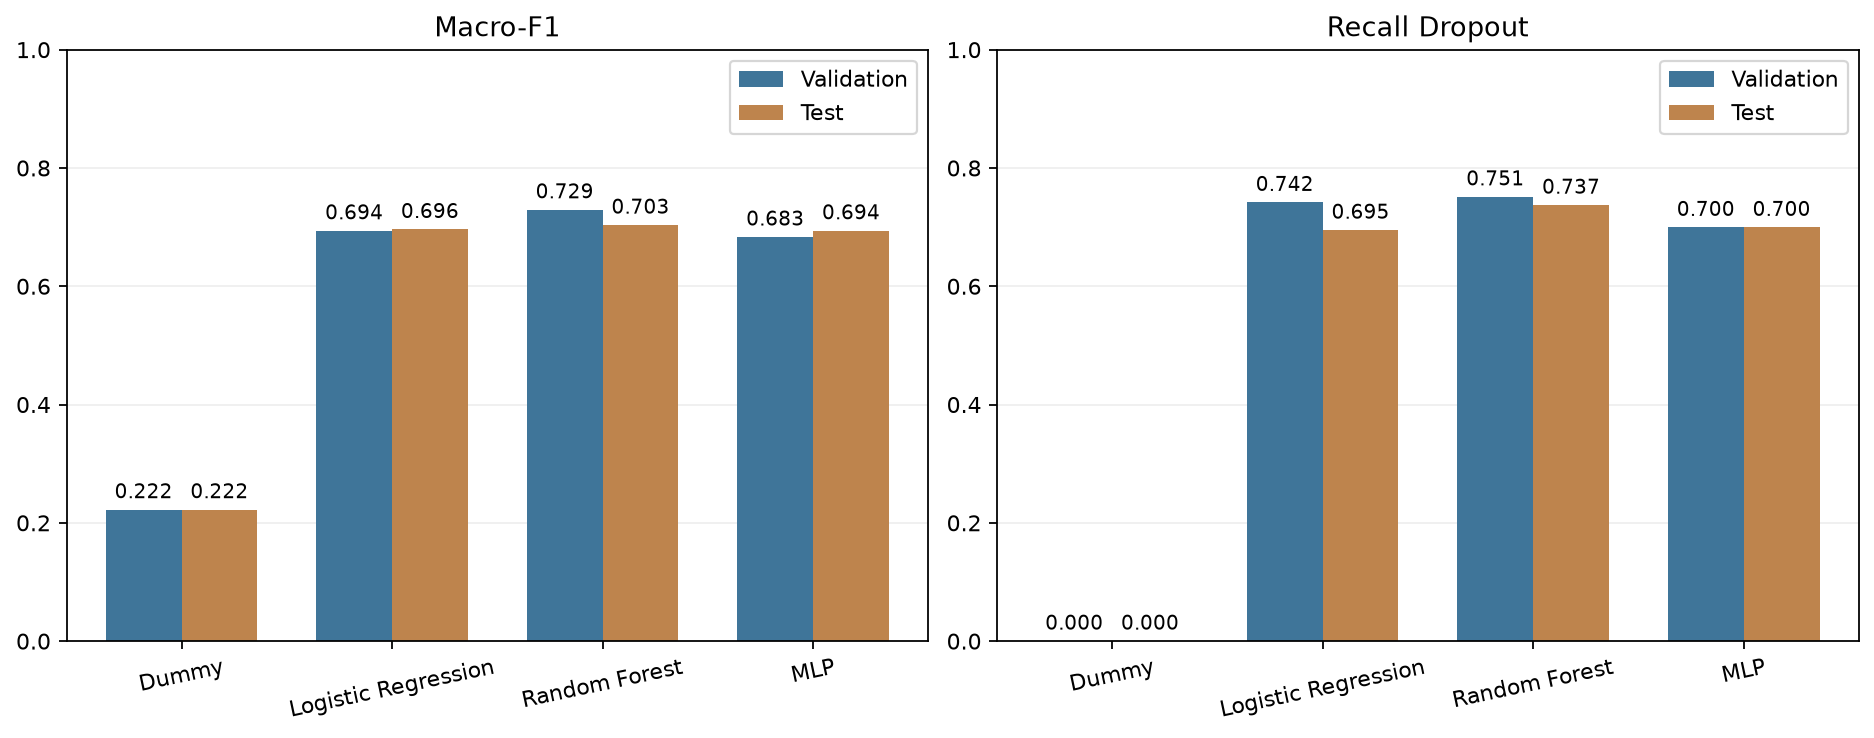

In [5]:
def save_figure(figure, filename):
    path = figure_dir / filename
    figure.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(figure)
    display(Image(filename=str(path)))


figure, axes = plt.subplots(1, 2, figsize=(11.6, 4.5), layout="constrained")
positions = np.arange(len(model_names))
width = 0.36
for ax, metric, title in zip(
    axes, ("macro_f1", "dropout_recall"), ("Macro-F1", "Recall Dropout"),
):
    for shift, values, label, color in (
        (-width / 2, validation_summary[metric], "Validation", "#3F7599"),
        (width / 2, test_summary[metric], "Test", "#BE844D"),
    ):
        bars = ax.bar(positions + shift, values, width, label=label, color=color)
        ax.bar_label(bars, labels=[f"{value:.3f}" for value in values], padding=3, fontsize=9)
    ax.set(xticks=positions, xticklabels=model_names, ylim=(0, 1), title=title)
    ax.tick_params(axis="x", labelrotation=12)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend()
save_figure(figure, "metric_comparison.png")

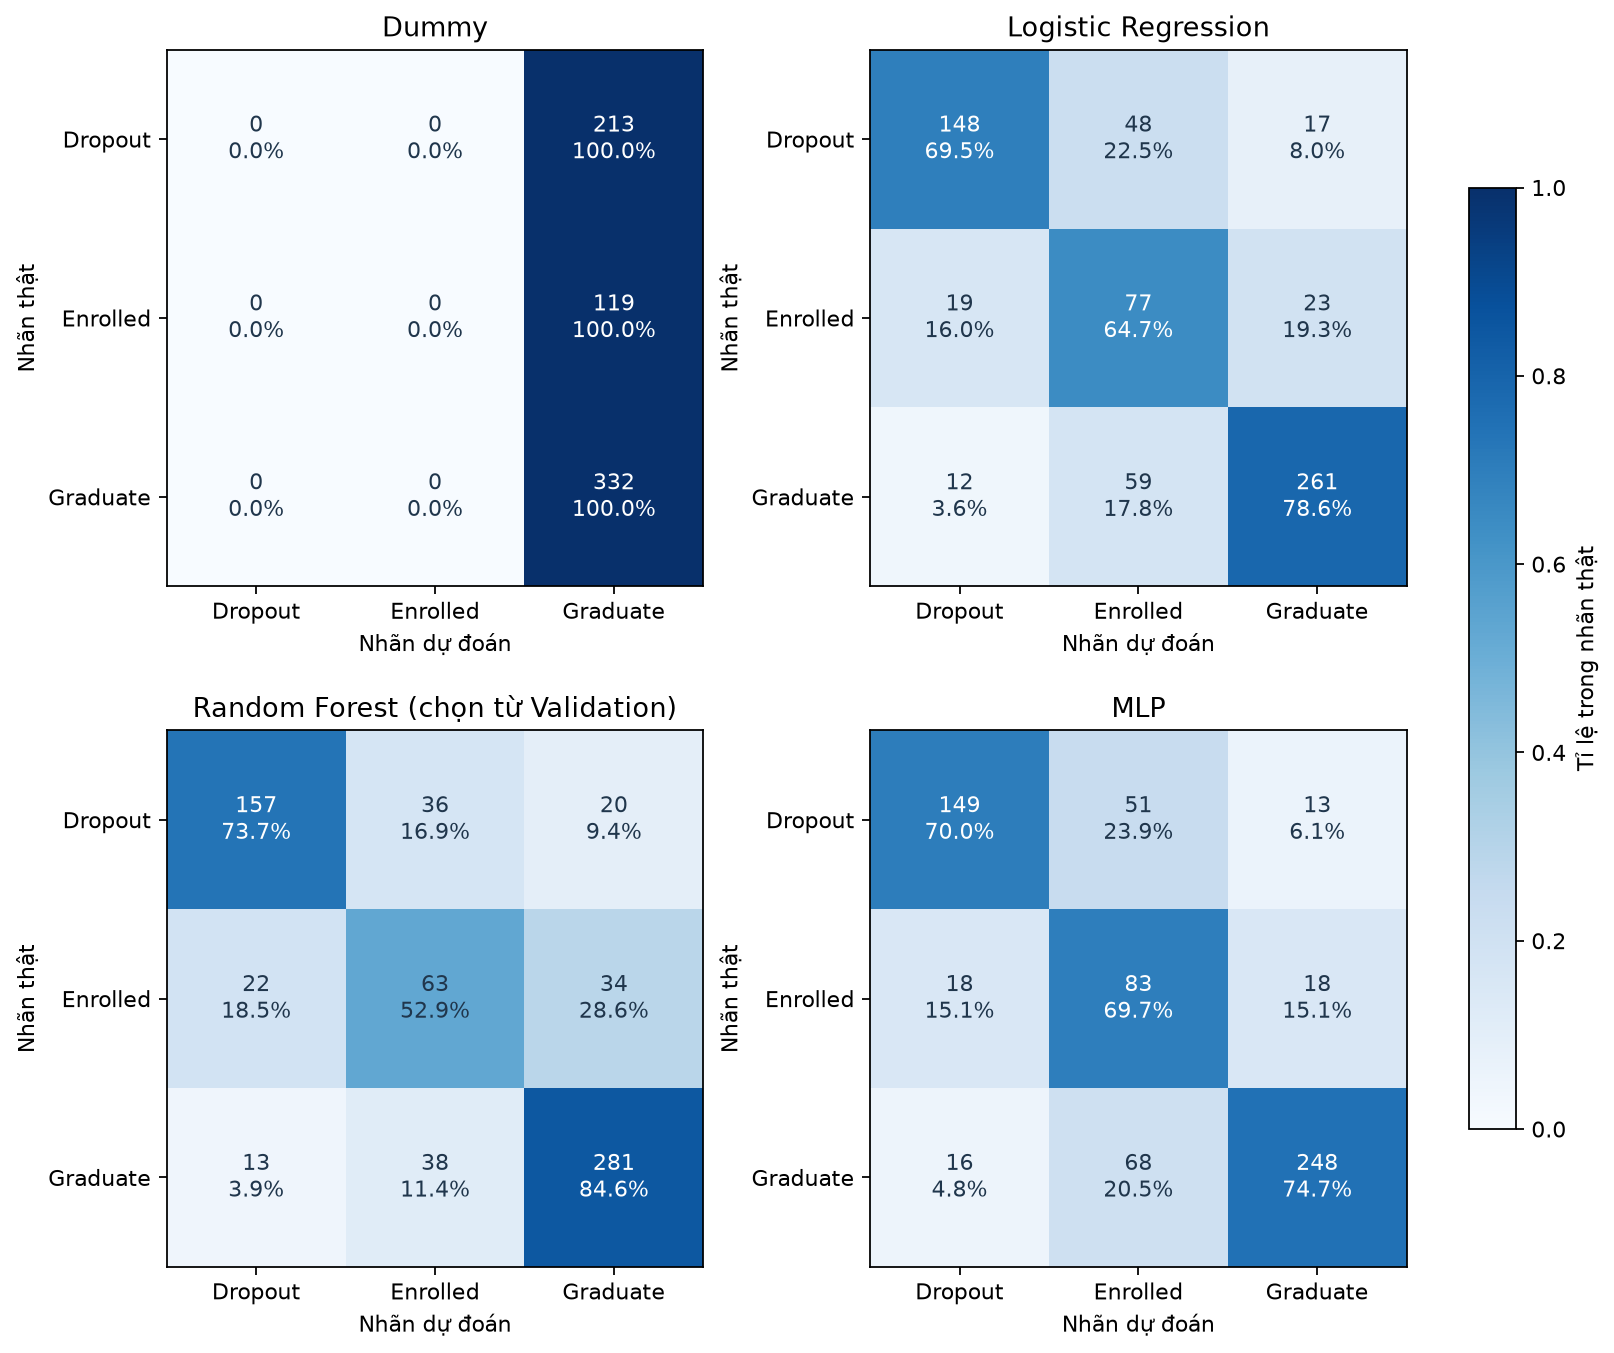

In [6]:
figure, axes = plt.subplots(2, 2, figsize=(10, 8.5), layout="constrained")
for ax, name in zip(axes.flat, model_names):
    counts = np.asarray(test_results[name]["confusion_matrix"])
    shares = counts / counts.sum(axis=1, keepdims=True)
    color_map = ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
    for row in range(len(LABELS)):
        for column in range(len(LABELS)):
            ax.text(column, row, f"{counts[row, column]}\n{shares[row, column]:.1%}",
                    ha="center", va="center",
                    color="white" if shares[row, column] >= 0.55 else "#20364C")
    title = name
    if name == manifest["selected_model"]:
        title += " (chọn từ Validation)"
    ax.set(xticks=range(len(LABELS)), xticklabels=LABELS,
           yticks=range(len(LABELS)), yticklabels=LABELS,
           xlabel="Nhãn dự đoán", ylabel="Nhãn thật", title=title)
figure.colorbar(color_map, ax=list(axes.flat), shrink=0.75, label="Tỉ lệ trong nhãn thật")
save_figure(figure, "confusion_matrices.png")

### Nhận xét kết quả Test

**Random Forest được chọn từ Validation trước khi chấm Test.** Trên Test, mô hình đạt **Macro-F1 0,7034**, accuracy **75,45%** và F2 Dropout **0,7519**.

Trong bốn phương pháp đã chốt, **Random Forest** có Macro-F1 Test cao nhất quan sát được. Logistic đạt **0,6960**, MLP đạt **0,6938** và Dummy đạt **0,2222**. Khoảng cách giữa hai mô hình đứng đầu là **0,0074**. Đây là chênh lệch quan sát trên 664 mẫu của một bộ chia cố định.

- **Nhận diện Dropout.** Random Forest nhận ra **157/213** ca (**73,71%**). Trong **56** ca bị bỏ sót, **36** được gán Enrolled và **20** được gán Graduate.
- **Phân biệt Enrolled.** MLP có F1 Enrolled cao nhất trong bảng, đạt **0,5171**. F1 Enrolled của Random Forest là **0,4922**. Vì vậy, bảng từng lớp cần được trình bày cùng Macro-F1 để thấy rõ thế mạnh của từng phương pháp.
- **Đối chiếu Validation và Test.** Macro-F1 của Random Forest trên Validation là **0,7293**, trên Test là **0,7034**, chênh **-0,0259** điểm khi lấy Test trừ Validation.

Phân tích trong báo cáo cần gắn với dữ liệu có sẵn đến học kỳ 2 và bộ chia hiện tại. Các kết quả ở đây phục vụ đánh giá mô hình đã chốt.

## 6. Lưu thông tin để tái hiện lượt đánh giá

File `evaluation.json` ghi phiên bản thư viện đang dùng, mã nhận diện mô hình và dữ liệu, số mẫu Test, mô hình được chọn trên Validation và các điểm Test. Mã nhận diện các bảng, hình giúp đối chiếu bộ bàn giao sau khi sao chép hoặc nén bài.

In [7]:
output_paths = [
    table_dir / name for name in (
        "test_summary.csv", "test_per_class.csv", "test_confusion.csv",
        "predictions_test.csv", "validation_vs_test.csv",
    )
] + [figure_dir / "metric_comparison.png", figure_dir / "confusion_matrices.png"]
evaluation_metadata = {
    "created_utc": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "notebook": "notebooks/evaluation/07_evaluate_test.ipynb",
    "source_manifest": str(manifest_path.relative_to(root)).replace("\\", "/"),
    "source_manifest_sha256": file_sha256(manifest_path),
    "input_sha256": manifest["input_sha256"],
    "hash_mode": manifest["hash_mode"],
    "labels": list(LABELS),
    "feature_columns": list(FEATURE_COLUMNS),
    "n_train": len(train_rows), "n_validation": len(validation_rows), "n_test": len(test_rows),
    "test_rows_sha256": hashlib.sha256(json.dumps(test_rows).encode("utf-8")).hexdigest(),
    "selected_model_on_validation": manifest["selected_model"],
    "selection_metric": manifest["selection_metric"],
    "validation_reloaded_matches": bool(validation_check["matched"].all()),
    "runtime": {
        "python": platform.python_version(), "sklearn": sklearn.__version__,
        "torch": str(torch.__version__), "numpy": np.__version__,
        "pandas": pd.__version__, "joblib": joblib.__version__,
    },
    "model_load_warnings": load_warnings,
    "test": {
        name: {metric: float(result[metric]) for metric in SUMMARY_COLUMNS}
        for name, result in test_results.items()
    },
    "output_sha256": {
        str(path.relative_to(root)).replace("\\", "/"): file_sha256(path) for path in output_paths
    },
}
(table_dir / "evaluation.json").write_text(
    json.dumps(evaluation_metadata, ensure_ascii=False, indent=2) + "\n", encoding="utf-8",
)
print("Bảng kết quả cuối nằm trong reports/tables/test/.")
print("Biểu đồ nằm trong reports/figures/test/.")

Bảng kết quả cuối nằm trong reports/tables/test/.
Biểu đồ nằm trong reports/figures/test/.


Báo cáo dùng `test_summary.csv` cho bảng kết quả cuối và `test_per_class.csv` để phân tích từng lớp. Kèm mô tả bộ chia, cách chọn cấu hình của từng phương pháp và mốc dự đoán có dữ liệu học kỳ 2.